# Analisi statistica e critica delle campagne approvate

Analisi completamente offline delle nove combinazioni: nessuna connessione DB, ingestione o riesecuzione delle query. Gli originali sono aperti solo in lettura. Il catalogo proviene da `config/demo.yaml`; le impostazioni DEMO live non vengono utilizzate.

100K deriva dal controllo funzionale preliminare approvato; 1M e FULL da campagne successive. Le dimensioni sono prefissi ordinati del CSV, non campioni casuali. Le 20 misure sono ripetizioni sequenziali nella stessa sessione: non stimano la variabilità fra esecuzioni complete indipendenti. Nessun p-value, intervallo di confidenza o dichiarazione di significatività.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src').is_dir() and (p/'config').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from IPython.display import display, HTML, SVG
from src.statistical_analysis import load_analysis_catalog, analyze_campaigns, export_analysis
from src.statistical_plots import distribution_chart, growth_chart
from src.presentation import html_table
campaigns, results_root = load_analysis_catalog(ROOT/'config/demo.yaml')
analysis = analyze_campaigns(campaigns, results_root)
def table(name, columns):
    display(HTML(html_table(analysis[name], columns)))
print('Serie query:', len(analysis['queries']), '| misure:', sum(g['n'] for g in analysis['queries']))
print('Sorgenti verificate:', len(analysis['source_hashes']))


Serie query: 54 | misure: 1080
Sorgenti verificate: 246


## Vista sintetica iniziale
Cinque grafici principali per una dimensione selezionata: ingestione, lookup Q1, Q2/Q3 prima e dopo gli indici e aggregazione Q4. Cambiare `DIMENSIONE_SINTESI` per 100K, 1M o FULL.
I restanti **22 grafici** rimangono nelle sezioni successive, attivabili con `MOSTRA_APPROFONDIMENTI=True`: totale **27**. Tutti derivano soltanto dagli artefatti storici FULL; nessuna misura LIVE.


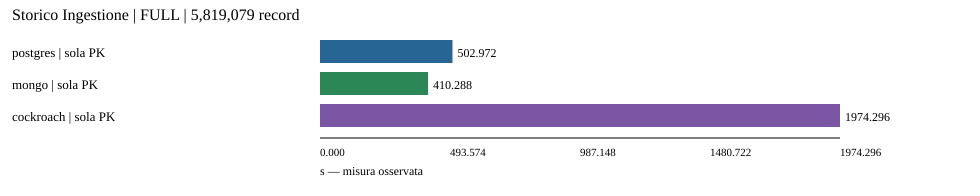

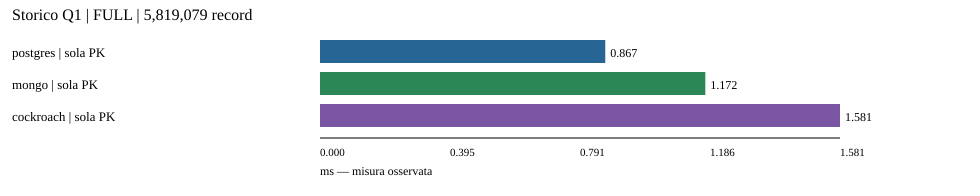

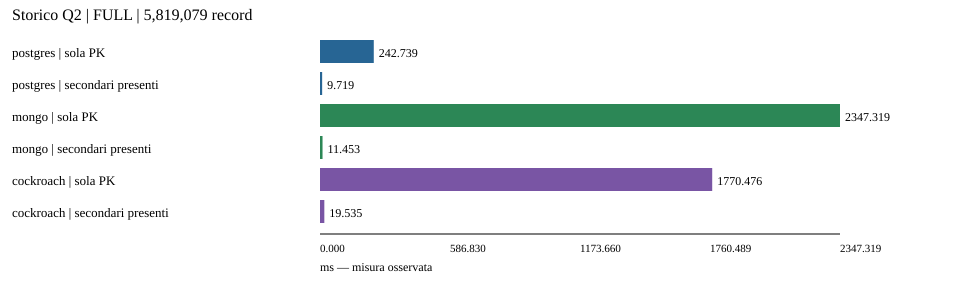

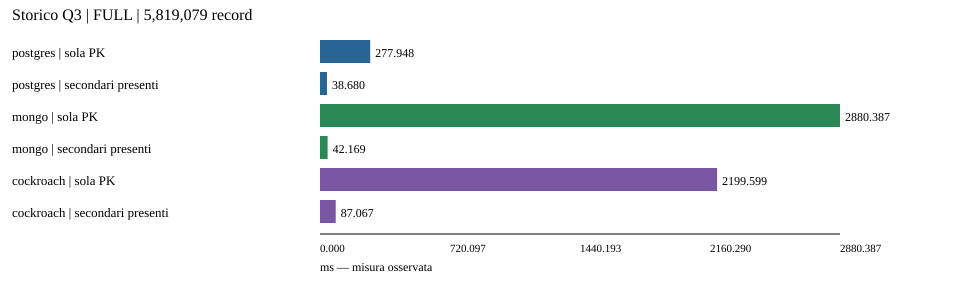

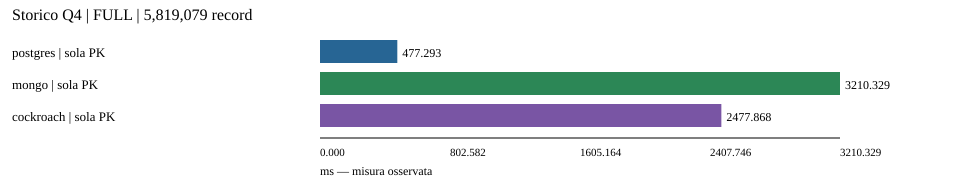

In [2]:
from src.history import read_catalog
from src.presentation import historical_charts
DIMENSIONE_SINTESI = 5819079
MOSTRA_APPROFONDIMENTI = False
summaries = read_catalog(campaigns, results_root)
for svg in historical_charts(summaries, DIMENSIONE_SINTESI).values():
    display(SVG(svg))


## Controlli e convenzioni

Si verificano manifest completati, protocollo comune, riferimenti e snapshot coerenti. Dai raw si controllano identità, ordine delle 23 iterazioni, 3 warm-up, 20 misure, parametri e digest. Q4 mantiene la tolleranza numerica approvata tramite gli snapshot: un digest differente per arrotondamento non dimostra una differenza logica. Le cinque statistiche storiche sono ricalcolate e confrontate con i CSV originali.

Tempi in **millisecondi**, deviazione standard **campionaria (n-1)**. Quantili con interpolazione lineare nella posizione (n-1)p; MAD = mediana degli scarti assoluti dalla mediana, senza fattore di scala. CV = 100s/media. I punti oltre 1,5 IQR sono soltanto segnalati e restano inclusi.


In [3]:
table('queries', ['database','dataset_size','query_id','index_state','category','n','mean_ms','median_ms','sample_stddev_ms','min_ms','max_ms','iqr_ms','mad_ms','cv_pct','tukey_flags'])

database,dataset_size,query_id,index_state,category,n,mean_ms,median_ms,sample_stddev_ms,min_ms,max_ms,iqr_ms,mad_ms,cv_pct,tukey_flags
postgres,100000,Q1,primary_only,lookup PK,20,0.8517038,0.6600455000000001,0.33306765971979485,0.567637,1.787688,0.41640274999999993,0.08230950000000009,39.10604364096942,1
postgres,100000,Q2,primary_only,scansione filtrata,20,8.5861962,7.8684505,1.5409937576802972,7.060499,11.77335,1.7627995000000007,0.4357234999999995,17.947339215009986,0
postgres,100000,Q3,primary_only,scansione filtrata,20,9.7019864,9.036467,1.614655696483257,8.461127,14.146548,0.6288422499999999,0.30602399999999985,16.642526900298037,4
postgres,100000,Q4,primary_only,aggregazione,20,15.394650350000001,14.5787145,1.9386201620658274,13.837436,21.083199,1.0977115000000008,0.4707379999999999,12.592817101986519,3
postgres,100000,Q2,secondary,conteggio indicizzato,20,0.71573215,0.6119085,0.22402637900415467,0.530739,1.3007,0.2734675,0.060517499999999946,31.30030962059685,1
postgres,100000,Q3,secondary,conteggio indicizzato,20,0.8979847,0.8138225,0.27003623958317347,0.687209,1.915781,0.08273574999999989,0.03661550000000002,30.07136308482466,2
mongo,100000,Q1,primary_only,lookup PK,20,1.03712325,0.8978635,0.3115782101752092,0.752544,1.772877,0.3080464999999999,0.07236300000000001,30.0425441407479,2
mongo,100000,Q2,primary_only,scansione filtrata,20,22.3574592,21.022621,3.1717048382832425,19.342967,29.701174,3.4616412499999996,1.3823495000000001,14.186338482877527,1
mongo,100000,Q3,primary_only,scansione filtrata,20,30.9564516,29.810454,4.212918279757286,26.02574,40.269062,5.624251499999996,2.394240999999999,13.609176963154543,0
mongo,100000,Q4,primary_only,aggregazione,20,35.77783635,35.1293465,3.289177253475568,31.61252,44.587669,3.1342077499999945,1.9037269999999964,9.193337521304773,2


## Distribuzione e ordine delle misure

Selezionare dimensione, query e scenario. Baffi min/max, box IQR, mediana e **tutti i 20 punti**. La traccia usa l'ordine locale delle sessioni, non un tempo comune fra DB. Lag-1 e confronto delle due metà sono indizi descrittivi di variazione temporale, non test di indipendenza. Correlazione nulla non prova indipendenza.


## Approfondimenti: altre dimensioni
Ingestione, Q1-Q4 e confronto baseline/indici: ogni grafico mantiene separati i dataset. Le barre mostrano medie; la dispersione delle query rimane nelle tabelle e nei grafici dei punti. Ingestione: un solo evento per motore e dimensione.

In [4]:
if MOSTRA_APPROFONDIMENTI is True:
    for size in (100000, 1000000, 5819079):
        if size != DIMENSIONE_SINTESI:
            for svg in historical_charts(summaries, size).values():
                display(SVG(svg))

else:
    print('Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.')


Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.


In [5]:
if MOSTRA_APPROFONDIMENTI is True:
    DIMENSIONE = 5819079
    QUERY = 'Q3'
    SCENARIO = 'secondary'
    selected = [g for g in analysis['queries'] if (g['dataset_size'],g['query_id'],g['index_state']) == (DIMENSIONE,QUERY,SCENARIO)]
    display(SVG(distribution_chart(selected)))
    display(SVG(distribution_chart(selected, temporal=True)))
    for g in selected:
        print(g['database'], '20 misure ms:', g['values_ms'])

else:
    print('Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.')


Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.


In [6]:
table('queries', ['database','dataset_size','query_id','index_state','lag1_descriptive','first_half_mean_ms','last_half_mean_ms','excluded_observations'])

database,dataset_size,query_id,index_state,lag1_descriptive,first_half_mean_ms,last_half_mean_ms,excluded_observations
postgres,100000,Q1,primary_only,0.010472692263680073,0.8838807,0.8195269,0
postgres,100000,Q2,primary_only,0.18469158900796387,9.068442300000001,8.1039501,0
postgres,100000,Q3,primary_only,-0.05122021056342275,10.4691804,8.9347924,0
postgres,100000,Q4,primary_only,-0.08824647057451553,15.6201905,15.1691102,0
postgres,100000,Q2,secondary,0.08420443105479243,0.6779466000000001,0.7535177,0
postgres,100000,Q3,secondary,0.2841847952034144,0.9937234,0.802246,0
mongo,100000,Q1,primary_only,0.37431504818691724,1.2248276,0.8494189,0
mongo,100000,Q2,primary_only,0.5018151920410564,22.6142932,22.1006252,0
mongo,100000,Q3,primary_only,0.22559191708613677,31.0883601,30.8245431,0
mongo,100000,Q4,primary_only,0.1664415334802315,35.538647,36.0170257,0


## Selettività e crescita

Q1 è un lookup su PK, Q2/Q3 sono conteggi filtrati (non trasferimenti di tutti i record), Q4 aggrega l'intera relazione. La baseline ha soltanto PK; lo scenario secondary aggiunge gli indici approvati. I piani originali rimangono la fonte per l'accesso effettivamente scelto dal planner.

I rapporti di tempo vengono affiancati al rapporto N e, per Q2/Q3, al rapporto dei record corrispondenti. Il rapporto tempo/matches è solo una normalizzazione descrittiva, non un costo unitario causale. Prefissi, cache, concorrenza interna e selettività possono cambiare insieme. I grafici usano assi logaritmici; le linee collegano osservazioni, non regressioni.


In [7]:
table('selection', ['dataset_size','Q2_rows','Q2_selectivity_pct','Q3_rows','Q3_selectivity_pct','Q4_groups'])
table('growth', ['database','query_id','index_state','from_size','to_size','row_ratio','mean_time_ratio','time_ratio_over_row_ratio','matching_row_ratio','time_ratio_over_matching_ratio'])

dataset_size,Q2_rows,Q2_selectivity_pct,Q3_rows,Q3_selectivity_pct,Q4_groups
100000,1827,1.827,7043,7.043,14
1000000,18012,1.8012,64503,6.4503,14
5819079,93811,1.612127967329538,413921,7.113170314408861,14


database,query_id,index_state,from_size,to_size,row_ratio,mean_time_ratio,time_ratio_over_row_ratio,matching_row_ratio,time_ratio_over_matching_ratio
postgres,Q1,primary_only,100000,1000000,10.0,0.9264261237298694,0.09264261237298695,None,None
postgres,Q1,primary_only,1000000,5819079,5.819079,1.0992979892734298,0.18891271097598603,None,None
postgres,Q1,primary_only,100000,5819079,58.19079,1.0184183750266231,0.01750136705527839,None,None
postgres,Q2,primary_only,100000,1000000,10.0,4.447035807311275,0.44470358073112753,9.858784893267652,0.4510734188295414
postgres,Q2,primary_only,1000000,5819079,5.819079,6.357236552523438,1.0924815683931148,5.208250055518543,1.2206089348163027
postgres,Q2,primary_only,100000,5819079,58.19079,28.270858584619813,0.4858304653471763,51.34701696770662,0.5505842452814744
postgres,Q3,primary_only,100000,1000000,10.0,4.431156371235483,0.4431156371235483,9.158455203748403,0.48383229187187426
postgres,Q3,primary_only,1000000,5819079,5.819079,6.465257189409456,1.1110447528568448,6.417081376060028,1.0075074337578382
postgres,Q3,primary_only,100000,5819079,58.19079,28.648565586527724,0.4923213035349361,58.77055232145393,0.4874646307530054
postgres,Q4,primary_only,100000,1000000,10.0,4.197523018117784,0.4197523018117784,None,None


In [8]:
if MOSTRA_APPROFONDIMENTI is True:
    for query, state in [('Q1','primary_only'),('Q2','primary_only'),('Q3','primary_only'),('Q4','primary_only'),('Q2','secondary'),('Q3','secondary')]:
        display(SVG(growth_chart(analysis['queries'], query, state)))

else:
    print('Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.')


Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.


## Indici: beneficio e costo

Speedup = media baseline / media indicizzata. Risparmio = differenza delle medie; riduzione percentuale rispetto alla baseline. Ammortamento **ipotetico** per una sola query e il relativo indice: ceil(costo costruzione / risparmio per query), soltanto se il risparmio è positivo. Non è una soglia di workload misurata: esclude manutenzione, nuove scritture, occupazione disco, cache e variabilità futura. Costruzione e ingestione sono singoli eventi, senza stima della loro incertezza.


In [9]:
table('index_benefits', ['database','dataset_size','query_id','before_mean_ms','after_mean_ms','speedup','reduction_pct','build_ms_single_event','saved_ms_per_query','build_over_saving_queries','break_even_queries_hypothetical'])
table('single_events', ['database','dataset_size','event','query_id','n','mean_ms','rows_per_second','sample_stddev_ms','uncertainty'])

database,dataset_size,query_id,before_mean_ms,after_mean_ms,speedup,reduction_pct,build_ms_single_event,saved_ms_per_query,build_over_saving_queries,break_even_queries_hypothetical
postgres,100000,Q2,8.5861962,0.71573215,11.996381886715582,91.66415333020225,53.880035,7.87046405,6.845852373850815,7
postgres,100000,Q3,9.7019864,0.8979847,10.804177844010036,90.74432118354649,28.282095,8.804001699999999,3.21241362322772,4
mongo,100000,Q2,22.3574592,2.1147801,10.57200188331638,90.54105352007083,166.199657,20.2426791,8.210358726676649,9
mongo,100000,Q3,30.9564516,2.1159953,14.629735519733908,93.16460643699874,190.496002,28.8404563,6.605166021593077,7
cockroach,100000,Q2,40.4478025,1.7908047,22.586383931201432,95.57255378706914,1437.244357,38.6569978,37.1794096488269,38
cockroach,100000,Q3,40.17378325,2.8156095,14.268236859550305,92.99142557105324,1319.772195,37.35817375,35.327535115390916,36
postgres,1000000,Q2,38.18312195,1.49089375,25.610894102949995,96.09541160109356,632.480864,36.6922282,17.23746131067614,18
postgres,1000000,Q3,42.99101885,2.9552335,14.54741862191262,93.12592820767728,319.768895,40.035785350000005,7.987076866471409,8
mongo,1000000,Q2,195.6871876,3.3229352,58.88985966382973,98.3019147851456,1058.96379,192.3642524,5.504992620967865,6
mongo,1000000,Q3,283.96344750000003,8.19368405,34.65638237539804,97.11452860495363,1186.627977,275.76976345,4.302966221368023,5


database,dataset_size,event,query_id,n,mean_ms,rows_per_second,sample_stddev_ms,uncertainty
postgres,100000,ingestion,,1,8151.635933,12267.476224640171,None,non stimabile: singolo evento
postgres,100000,create_index,origin_airport,1,53.880035,None,None,non stimabile: singolo evento
postgres,100000,create_index,distance,1,28.282095,None,None,non stimabile: singolo evento
mongo,100000,ingestion,,1,6183.964996,16170.85479375828,None,non stimabile: singolo evento
mongo,100000,create_index,origin_airport,1,166.199657,None,None,non stimabile: singolo evento
mongo,100000,create_index,distance,1,190.496002,None,None,non stimabile: singolo evento
cockroach,100000,ingestion,,1,34750.549666,2877.652323808857,None,non stimabile: singolo evento
cockroach,100000,create_index,origin_airport,1,1437.244357,None,None,non stimabile: singolo evento
cockroach,100000,create_index,distance,1,1319.772195,None,None,non stimabile: singolo evento
postgres,1000000,ingestion,,1,81042.518141,12339.201976179624,None,non stimabile: singolo evento


## PostgreSQL / MongoDB: query indicizzate FULL

Le sessioni sono distinte: nessun appaiamento per numero di iterazione. Si confrontano medie, mediane, dispersione e punti. La differenza delle medie divisa per la radice della media delle varianze è una misura descrittiva della sua grandezza rispetto alla dispersione interna; **non** un test, una probabilità o una stima della variabilità fra campagne. Anche sovrapposizione dei range/IQR non dimostra uguaglianza o assenza di differenza.

La frazione delle 400 ricombinazioni con tempo MongoDB inferiore usa sempre gli stessi 40 dati: **non sono 400 prove indipendenti**. Nel FULL MongoDB ha medie e mediane inferiori in entrambe le query; per Q2 il divario è piccolo rispetto alla dispersione, per Q3 è più evidente anche nelle mediane. L'osservazione non basta a generalizzare ad altre sessioni o macchine.


In [10]:
if MOSTRA_APPROFONDIMENTI is True:
    table('pg_mongo_full', list(analysis['pg_mongo_full'][0]))
    for query in ('Q2','Q3'):
        groups = [g for g in analysis['queries'] if g['dataset_size']==5819079 and g['index_state']=='secondary' and g['query_id']==query and g['database'] in ('postgres','mongo')]
        display(SVG(distribution_chart(groups)))
        display(SVG(distribution_chart(groups, temporal=True)))
else:
    print('Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.')


Operazione disabilitata: MOSTRA_APPROFONDIMENTI=False.


## Interpretazione e limiti

**Evidenze misurate:** statistiche dei raw, conteggi e selettività, rapporti osservati, tempi singoli di ingestione/indici. Consultare le tabelle per motore, dimensione e classe di query: una graduatoria unica nasconderebbe carichi diversi.

**Interpretazioni plausibili:** differenze di accesso agli indici, cache e implementazione delle aggregazioni possono contribuire ai tempi; queste campagne non isolano causalmente tali fattori. Le politiche di commit e atomicità differiscono fra motori: stesso batch non equivale a identico lavoro o garanzie.

**Limiti:** ordine fisso dei motori/scenari, nessuna randomizzazione o replica indipendente delle sessioni, cache non svuotate, ambiente locale Docker/WSL2, versioni e carichi non isolati, una sola ingestione/costruzione per combinazione. Nessun intervallo di confidenza per n=1; SD assente non significa assenza di variabilità. Nessuna esclusione degli estremi o inferenza da queste sole 20 ripetizioni.


## Esportazione facoltativa dei soli derivati

Disabilitata per default. Una nuova directory UUID in `results/statistical_analysis/` conserva CSV, serie complete e mappa SHA-256 delle fonti. Prima di scrivere si verifica che le fonti non siano cambiate. Non vengono sovrascritti file delle campagne approvate.


In [11]:
ESPORTA_DERIVATI = False
if ESPORTA_DERIVATI:
    print(export_analysis(analysis))